# 03. 볼츠만 머신 (Boltzmann Machine) — RBM과 CD-1

## 🎯 이 노트북에서 배울 것
1. **에너지 기반 모델(Energy-Based Model)**의 아이디어: "좋은(자주 나오는) 상태는 에너지가 낮다"
2. **RBM(제한된 볼츠만 머신)**: visible ↔ hidden 이분 граф 구조라 조건부 확률을 명시적으로 수식으로 계산 가능
3. **Contrastive Divergence(CD-1)**로 근사 학습하고, 모델에서 **샘플을 생성**해보기

## 📖 핵심 개념
- 볼츠만 분포: `P(v) = exp(-E(v)) / Z` (에너지가 낮을수록 확률이 높음)
- RBM 에너지: `E(v, h) = -bᵀv - cᵀh - vᵀWh`
- 조건부 독립성 때문에:
  - `P(h=1 | v) = σ(Wᵀv + c)` (모든 hidden이 동시에 샘플링 가능)
  - `P(v=1 | h) = σ(Wh + b)`
- 학습은 정확한 gradient가 아니라 **CD-1**로 근사: 데이터에서 시작해 짧은 깁스 샘플링(1 step)만으로 "데이터 통계 − 모델 통계"를 추정
-응용: Netflix 추천 시스템의협조 필터링, 특징 추출(딥러닝 이전 시대의 representation learning)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록,환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (8, 4)


## 1) 학습 데이터: 3×3 "막대와 줄무늬(bars & stripes)" 패턴 6가지

가로 막대 3개 + 세로 막대 3개 = 총 6개의 9픽셀 이진 이미지입니다. RBM이 이 6개 패턴의 "분포"를 학습해서 **비슷한 막대 패턴을 스스로 생성**하는 것이 목표입니다.


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

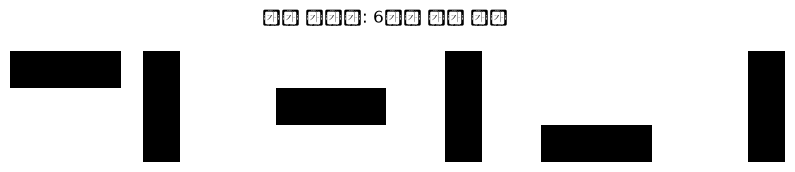

In [2]:
patterns = []
for i in range(3):
    p = np.zeros((3, 3)); p[i, :] = 1; patterns.append(p)   # 가로 막대
    p = np.zeros((3, 3)); p[:, i] = 1; patterns.append(p)   # 세로 막대
V_data = np.array([p.ravel() for p in patterns])            # (6개 샘플, 9차원 벡터)

fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax, p in zip(axes, patterns):
    ax.imshow(p, cmap="gray_r"); ax.axis("off")
plt.suptitle("학습 데이터: 6개의 막대 패턴"); plt.show()


## 2) RBM 직접 구현 (numpy) + CD-1 학습

가중치 갱신식의 핵심: `ΔW ∝ ⟨v·h⟩_데이터 − ⟨v·h⟩_모델`
- positive phase: 실제 데이터에서 `v·h`의 기댓값
- negative phase: 모델이 깁스 샘플링으로 만들어낸 `v·h`의 기댓값


In [3]:
class RBM:
    """제한된 볼츠만 머신: visible(9) ↔ hidden(6), CD-1로 학습"""
    def __init__(self, n_visible, n_hidden, lr=0.1, seed=0):
        r = np.random.default_rng(seed)
        self.W = r.normal(0, 0.01, (n_visible, n_hidden))  # visible-hidden 연결 가중치 (에너지의 vᵀWh 항)
        self.b = np.zeros(n_visible)   # visible 편향 (에너지의 -bᵀv 항)
        self.c = np.zeros(n_hidden)    # hidden 편향 (에너지의 -cᵀh 항)
        self.lr = lr

    @staticmethod
    def sigmoid(x):
        # clip: exp overflow 방지 (수치 안정성)
        return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

    def sample_hidden(self, v, rng):
        prob = self.sigmoid(v @ self.W + self.c)      # P(h=1 | v) — 이분 구조라 한 번에 샘플링 가능
        return (rng.random(prob.shape) < prob).astype(float), prob

    def sample_visible(self, h, rng):
        prob = self.sigmoid(h @ self.W.T + self.b)    # P(v=1 | h)
        return (rng.random(prob.shape) < prob).astype(float), prob

    def fit(self, V, epochs=4000, k=1, rng=None):
        rng = rng or np.random.default_rng(1)
        n = V.shape[0]
        recon_errors = []
        for epoch in range(epochs):
            # ── Positive phase: 실제 데이터 v0에서 시작 ──
            h0, h0_prob = self.sample_hidden(V, rng)
            # ── Negative phase: v0 → h0 → v1 → h1 ... k-step 깁스 샘플링 (모델의 샘플) ──
            v_neg = V.copy()
            h_prob = h0_prob
            for _ in range(k):
                h_s, h_prob = self.sample_hidden(v_neg, rng)
                v_neg, _ = self.sample_visible(h_s, rng)
            # ── CD-k 가중치 갱신: ΔW = η/N · (v0·h0ᵀ − vk·hkᵀ) ──
            self.W += self.lr * (V.T @ h0_prob - v_neg.T @ h_prob) / n
            self.b += self.lr * (V.mean(axis=0) - v_neg.mean(axis=0))
            self.c += self.lr * (h0_prob.mean(axis=0) - h_prob.mean(axis=0))
            # 재구성 오차 기록: 데이터를 hidden으로 압축했다가 다시 복원한 MSE
            recon = self.sigmoid(h0_prob @ self.W.T + self.b)
            recon_errors.append(((V - recon) ** 2).mean())
        return recon_errors


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51116 (\N{HANGUL SYLLABLE JAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

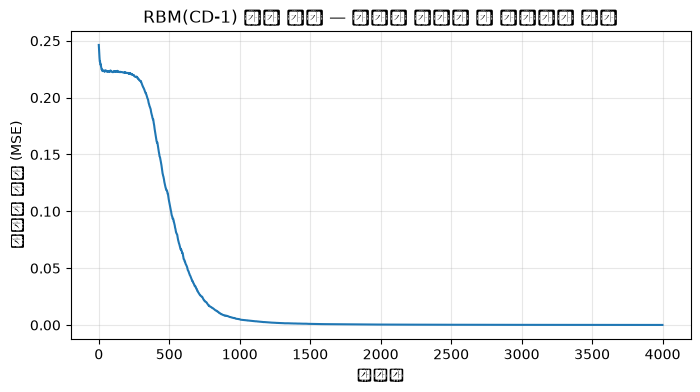

최종 재구성 오차: 8e-05


In [4]:
rbm = RBM(n_visible=9, n_hidden=6, lr=0.1, seed=0)
errs = rbm.fit(V_data, epochs=4000, k=1)

plt.plot(errs)
plt.xlabel("에포크"); plt.ylabel("재구성 오차 (MSE)")
plt.title("RBM(CD-1) 학습 곡선 — 데이터 패턴을 잘 복원하게 수렴")
plt.grid(alpha=0.3); plt.show()
print("최종 재구성 오차:", round(errs[-1], 5))


## 3) 학습된 모델에서 샘플 생성 + 가중치(필터) 시각화

- **깁스 샘플링**: 무작위 이진 벡터에서 시작해 `v → h → v → h ...`를 반복하면 볼츠만 분포 P(v)에 수렴
- **W의 각 열**은 hidden unit이 담당하는 "특징(필터)" — 막대 형태가 learns되는지 확인


/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 49368 (\N{HANGUL SYLLABLE SAEM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyp

/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 54620 (\N{HANGUL SYLLABLE HAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph 47561 (\N{HANGUL SYLLABLE MAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18823/3464428388.py:18: UserWarning: Glyph

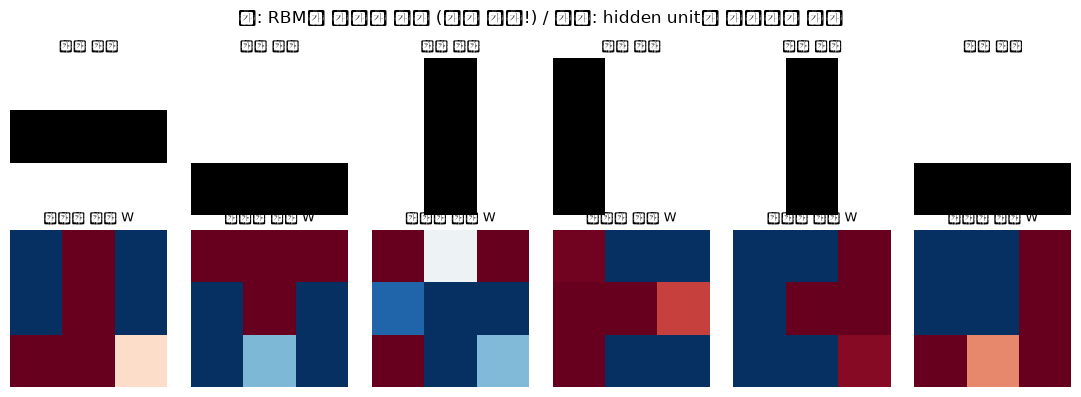

In [5]:
def gibbs_sample(model, n_samples=16, steps=200, seed=2):
    r = np.random.default_rng(seed)
    # 무작위 이진 상태에서 시작 (P(v) 샘플링의 초기화)
    v = (r.random((n_samples, model.W.shape[0])) < 0.5).astype(float)
    for _ in range(steps):                 # 충분히 긴 깁스 체인이 분포에 수렴
        h, _ = model.sample_hidden(v, r)
        v, _ = model.sample_visible(h, r)
    return v

samples = gibbs_sample(rbm, n_samples=12, steps=300)

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, s in zip(axes[0], samples[:6]):
    ax.imshow(s.reshape(3, 3), cmap="gray_r"); ax.axis("off"); ax.set_title("모델 샘플", fontsize=9)
for ax, w in zip(axes[1], rbm.W.T[:6]):
    ax.imshow(w.reshape(3, 3), cmap="RdBu_r", vmin=-1, vmax=1); ax.axis("off"); ax.set_title("학습된 필터 W", fontsize=9)
plt.suptitle("위: RBM이 생성한 샘플 (막대 패턴!) / 아래: hidden unit이 검출하는 특징")
plt.tight_layout(); plt.show()


## ✅ 정리

- 볼츠만 머신은 **에너지 기반 생성 모델**: 데이터 분포를 암묵적으로 학습해서 새로운 샘플을 생성
- RBM은 visible-hidden **이분 구조**라 `P(h|v)`, `P(v|h)`를 시그모이드로 **명시적으로** 계산 가능 → 깁스 샘플링이 효율적
- 정확한 gradient 대신 **CD-1** 근사만으로도 충분히 학습됨 (Hinton, 2002)
- 한계: 깊게 쌓기 어려움 → 이를 극복한 것이 **딥 빌리프 네트워크(DBN)**, 나아가 현대 생성 모델(GAN, VAE, Diffusion)
- 다음: [`04_CNN.ipynb`](./04_CNN.ipynb) — 이미지 처리의 핵심, 합성곱 신경망
